# 03 — Cung cầu và tồn kho

FAOSTAT SUA calendar years và USDA PSD marketing years được phân tích tách biệt.

Environment: Windows host, Python 3.10–3.13; `pip install -r requirements/analytics.txt`.
Docker `tlcn-local` đã healthy, Windows available >=2 GiB, WSL >=3 GiB, không active writer/DagRun.
Không start Spark. Mỗi notebook chạy độc lập, theo thứ tự cells. Query names/typed filters hiển thị
trong retrieval cells; kết quả là full scoped results/aggregates, **không phải 20-row sample consumer**.
Source-scoped identities không phải official crosswalk. Không forward-fill/interpolate.

Chạy `python scripts/run_eda_notebooks.py --notebook <filename>` từ repo root để execute và cập nhật
Markdown diễn giải bằng đúng measured evidence. Kết quả Markdown ghi batch cố định bên trên;
publication đổi sẽ fail closed. Không dùng outputs cũ như live query cache.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/gold/consumer.py').exists())
sys.path.insert(0, str(ROOT/'src'))  # repository bootstrap, no credentials
import pandas as pd
import numpy as np
get_ipython().run_line_magic('matplotlib', 'inline')
import matplotlib.pyplot as plt
from analytics.client import EDAClient
from analytics.methods import calendar_yoy, endpoint_change, monthly_calendar
from analytics.notebook import inspect_frame, label, resolve, annual_plot, save_evidence
pd.set_option('display.max_columns', 20)
plt.rcParams.update({'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
client = EDAClient()
findings = []
inventory = client.query('publication')
EXPECTED_BATCH = 'ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235'
assert client.batch == EXPECTED_BATCH, 'Publication changed: review scope before reproducing EDA'
display(inventory)
print('Published batch:', client.batch, '| No query cache | Windows/WSL/writer gates checked per request')

,table,rows,uuid,snapshot_id
0,dim_date,2038,0d029553-197b-4e46-8d62-17f21334a11b,7665947661409225898
1,dim_month,800,4f262a83-5e36-4d9e-b7e0-18f91b46327f,8295574410069434036
2,dim_observation_type,34,8adc0a9f-498e-4503-aa05-f95ae5a358ed,1046146616745412073
3,dim_price_series,1042,fa39bf1e-bbf1-4b50-8129-de1d4f37413b,2896601742107309180
4,dim_source_geography,987,ce487b86-5541-44de-a006-365dfbcc29f2,8664595598201008097
5,dim_source_product,295,4ce4f42f-e876-4870-8b2a-0312c460d673,8514812747103222137
6,dim_source_system,9,3c9fdb0f-127a-45f4-8f5b-31c7d1d5c0c1,5212267582300439758
7,dim_year,67,032861f7-4c4e-4ac4-9a10-274670b1d694,3316235776078407392
8,fact_fao_price_annual,9993,3218dd14-0793-4c1d-941c-31ba5e1aaea8,6561274137596983252
9,fact_fao_production_observation,22738,f97e800f-ebe6-416c-918a-a148ec0388b4,4557995850181557281


Published batch: ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235 | No query cache | Windows/WSL/writer gates checked per request


## Câu hỏi 1 — Supported SUA components của Viet Nam

In [2]:
geos=client.query('catalogue',kind='geographies');products=client.query('catalogue',kind='products')
vn=resolve(geos,'faostat_m49','704','geography_key')
sua_options=client.query('subject_products',fact='fact_fao_sua_observation',geography=vn)
display(sua_options)  # verify actual fact-specific product/metric availability
sua_product=resolve(products,'faostat_cpc','23161.02','product_key')
assert sua_product in set(sua_options.product_key)
sua=client.query('sua',geography=vn,product=sua_product,start_year=2010,end_year=2023)

,product_key,source_identity,source_labels_json,observations,numeric_observations,first_year,last_year,metric_codes
0,47b4dde0c6083d0e2ee5a313603df027c7c03d6ef2f46f...,0113,"[""Rice""]",132,132,2010,2023,"[5166, 5910, 5113, 5610, 5016, 5023, 5510, 552..."
1,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,23161.02,"[""Rice, milled""]",112,112,2010,2023,"[5141, 5166, 5071, 5510, 5610, 5910, 5023, 5113]"


In [3]:
display(sua.shape,inspect_frame(sua),sua.head())

(14, 39)

,dtype,nulls
year_key,int64,0
geography_key,object,0
product_key,object,0
loss_t,object,14
present_5016,int64,0
observation_5016,object,14
processed_t,object,0
present_5023,int64,0
observation_5023,object,0
stock_variation_t,object,0


,year_key,geography_key,product_key,loss_t,present_5016,observation_5016,processed_t,present_5023,observation_5023,stock_variation_t,...,observation_5520,seed_t,present_5525,observation_5525,import_quantity_t,present_5610,observation_5610,export_quantity_t,present_5910,observation_5910
0,2020,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,None,0,None,3500000.00,1,8f791a4acfc3e576f3ec15f8a6c07770cc5a1529a8e4f2...,-50000.00,...,None,None,0,None,35758.60,1,34120eb8671dc8e98a0355bceb7ae4581819ad0933a668...,4799008.65,1,01738745b540604dd3316827b1d4d14858a80125441e80...
1,2021,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,None,0,None,5000000.00,1,b1401942411a1ad3fcbed64662dee543907c7a67afd274...,-500000.00,...,None,None,0,None,346404.98,1,0d87f81e98802e39d7959d0b14d14f57755f47824bb0c6...,4958743.07,1,1ff04e7a239972ab031584d25191acd71982dd532c1388...
2,2015,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,None,0,None,3300000.00,1,cb09d86f3ac2767d865faa4e000de684d75a75beba137b...,200000.00,...,None,None,0,None,16575.61,1,2cb12cff6cea733c68cca02a1667a48263e9634dae00d1...,6048015.52,1,80c38a57ac2780a9e7c20a4c8adf14360dbf8468869d9a...
3,2016,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,None,0,None,4000000.00,1,1162656806467a93952e7db4f201ec4829d0846cb5a730...,547423.47,...,None,None,0,None,38861.20,1,73d59de210f9afdf631ca9734337db20257f2ae4b39ead...,4489037.36,1,ba687ca256927835f026e350f8328e5163d55fed591ce8...
4,2017,454338b3e9b9203015ec55fa27305ffba31eac866ae497...,9b20a1844ec8b08d320fceaf8f4360279d9a41fa491578...,None,0,None,3000000.00,1,48c4dfa5cf85b2c0b3d10ea73f0e144d606facea97f9a9...,270000.00,...,None,None,0,None,36376.00,1,6e5a3ee6ff8901a2fd238b4b7fd8adff31e85e8c441ff7...,5338505.60,1,d54ce300d804e623c6092c55cd0d0c06085702fc3b0150...


In [4]:
value_columns=['food_supply_quantity_t','production_t','import_quantity_t','export_quantity_t','opening_stocks_t','stock_variation_t','residuals_t','feed_t','seed_t','loss_t','processed_t','other_uses_t']
for col in value_columns:sua[col]=pd.to_numeric(sua[col])
assert not sua.year_key.duplicated().any()
display(sua[['year_key']+value_columns])

,year_key,food_supply_quantity_t,production_t,import_quantity_t,export_quantity_t,opening_stocks_t,stock_variation_t,residuals_t,feed_t,seed_t,loss_t,processed_t,other_uses_t
0,2020,14507206.95,22720457.00,35758.60,4799008.65,6368677.81,-50000.00,0.0,NaN,NaN,NaN,3500000.00,NaN
1,2021,14351182.58,23463520.67,346404.98,4958743.07,6318677.81,-500000.00,0.0,NaN,NaN,NaN,5000000.00,NaN
2,2015,14396435.62,23927875.53,16575.61,6048015.52,4505550.00,200000.00,0.0,NaN,NaN,NaN,3300000.00,NaN
3,2016,13900000.00,22897599.63,38861.20,4489037.36,4705550.00,547423.47,0.0,NaN,NaN,NaN,4000000.00,NaN
4,2017,14126870.46,22699000.06,36376.00,5338505.60,5252973.47,270000.00,0.0,NaN,NaN,NaN,3000000.00,NaN
5,2022,13859971.47,22938971.36,124176.00,4808804.75,5818677.81,294333.50,0.0,NaN,NaN,NaN,4100037.63,NaN
6,2010,14050000.00,21754883.27,983.00,6892959.00,5917024.29,-87092.73,0.0,NaN,NaN,NaN,900000.00,NaN
7,2011,14150000.00,23127222.14,2409.00,7112000.00,5829931.56,867631.14,0.0,NaN,NaN,NaN,1000000.00,NaN
8,2012,14100000.00,23773906.79,2100.00,8015000.00,6697562.70,-1335388.70,0.0,NaN,NaN,NaN,2996395.49,NaN
9,2013,14150000.00,23329375.81,2200.00,6722000.00,5362174.01,-836624.01,0.0,NaN,NaN,NaN,3296199.82,NaN


In [5]:
flow=sua[['year_key','food_supply_quantity_t','production_t','import_quantity_t','export_quantity_t']].melt('year_key',var_name='metric',value_name='value')
stock=sua[['year_key','opening_stocks_t','stock_variation_t','residuals_t']].melt('year_key',var_name='metric',value_name='value')

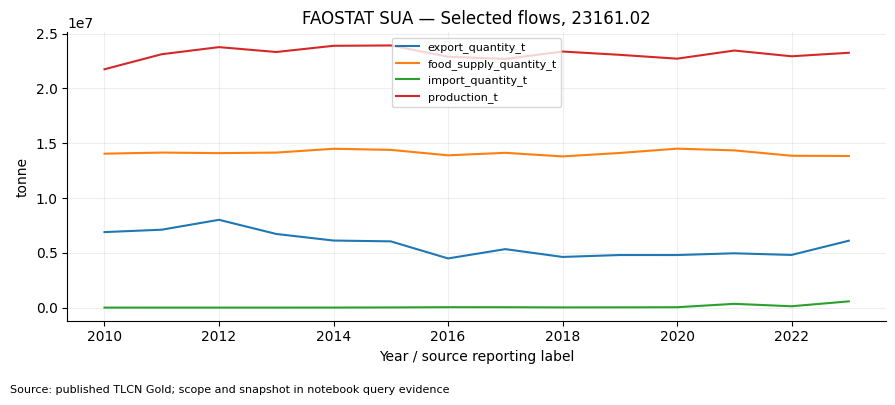

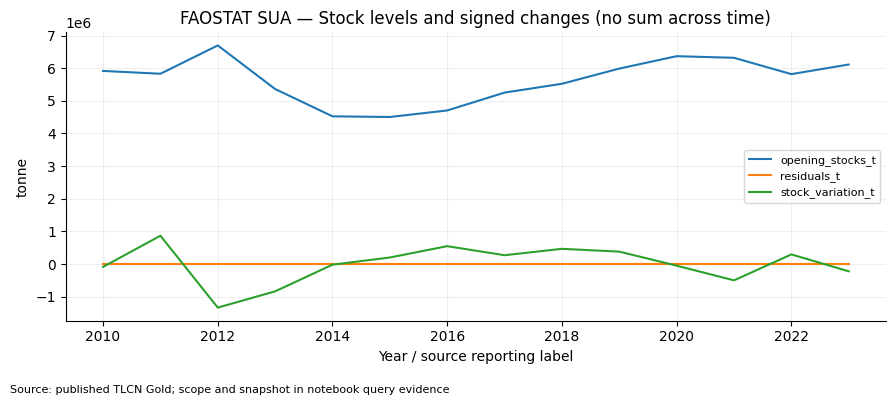

In [6]:
annual_plot(flow,'value','FAOSTAT SUA — Selected flows, 23161.02','tonne',group='metric')
annual_plot(stock,'value','FAOSTAT SUA — Stock levels and signed changes (no sum across time)','tonne',group='metric')

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** 5071/5166 giữ signed; opening stocks không cộng qua năm. 12 supported codes không chứng minh một accounting identity đầy đủ.

In [7]:
for identifier,col in [('SUA01','food_supply_quantity_t'),('SUA02','opening_stocks_t')]:
    stat=endpoint_change(sua,value=col)
    findings.append(dict(id=identifier,title='SUA '+col,observation=f"{stat['first_year']}–{stat['last_year']}: {stat['first_value']:,.2f} → {stat['last_value']:,.2f} tonnes ({stat['change_pct']:+.2f}%).",scope='FAOSTAT Viet Nam, 23161.02; calendar years',interpretation='Reported component trend; opening stock is not annual flow and no closing stock is invented.',query='sua',cell='Câu hỏi 1',numbers=stat))

## Câu hỏi 2 — USDA production, consumption và ending stocks

In [8]:
psd_geo=resolve(geos,'usda_psd_country','Vietnam','geography_key')
psd_product=resolve(products,'usda_psd','Rice, Milled','product_key')
psd=client.query('psd',geography=psd_geo,product=psd_product,start_year=1960,end_year=2025)

In [9]:
display(psd.shape,inspect_frame(psd),psd[['metric','unit']].drop_duplicates())

(990, 10)

,dtype,nulls
market_year,int64,0
crop_year,object,0
geography_key,object,0
product_key,object,0
metric,object,0
unit,object,0
value,object,0
observation_key,object,0
missing_reason,object,990
dq_warnings_json,object,0


,metric,unit
0,Imports,tonne
1,Production,tonne
2,TY Imports,tonne
3,Total Distribution,tonne
4,Yield,tonne/hectare
5,Area Harvested,hectare
6,Beginning Stocks,tonne
7,Domestic Consumption,tonne
8,Ending Stocks,tonne
9,Exports,tonne


In [10]:
psd['value']=pd.to_numeric(psd.value)
assert not psd.duplicated(['market_year','metric']).any()
core=psd[psd.metric.isin(['Production','Domestic Consumption','Ending Stocks'])].copy()
assert core.unit.eq('tonne').all()
milling=psd[psd.metric=='Milling Rate (.9999)']
assert milling.unit.eq('fraction').all() and milling.value.between(0,1).all()
display(psd.pivot(index='market_year',columns='metric',values='value').tail(),milling.tail())

metric,Area Harvested,Beginning Stocks,Domestic Consumption,Ending Stocks,Exports,Imports,Milling Rate (.9999),Production,Rough Production,TY Exports,TY Imp. from U.S.,TY Imports,Total Distribution,Total Supply,Yield
market_year,,,,,,,,,,,,,,,
2021,7100000.0,3289000.0,22050000.0,3605000.0,7054000.0,2750000.0,0.625,26670000.0,42672000.0,7054000.0,0.0,2750000.0,32709000.0,32709000.0,6.01
2022,7120000.0,3605000.0,22250000.0,3770000.0,8225000.0,3500000.0,0.625,27140000.0,43424000.0,8225000.0,0.0,3500000.0,34245000.0,34245000.0,6.10
2023,7110000.0,3770000.0,22300000.0,3335000.0,9035000.0,3700000.0,0.625,27200000.0,43520000.0,9035000.0,0.0,3700000.0,34670000.0,34670000.0,6.12
2024,7020000.0,3335000.0,22300000.0,3347000.0,8063000.0,3525000.0,0.625,26850000.0,42960000.0,8063000.0,0.0,3525000.0,33710000.0,33710000.0,6.12
2025,6800000.0,3347000.0,22250000.0,2297000.0,8100000.0,3100000.0,0.625,26200000.0,41920000.0,8100000.0,0.0,3100000.0,32647000.0,32647000.0,6.17


,market_year,crop_year,geography_key,product_key,metric,unit,value,observation_key,missing_reason,dq_warnings_json
924,1983,1983/1984,c11f7acf2d86d0dedf53a3db9f0ed36ca33108d40f7db8...,2bc6ec06dc9145fb58911ef62ec2a076a4e94fc9a35d0e...,Milling Rate (.9999),fraction,0.65,8b06564263b143c674f70b2707c765005864da162d0e1b...,None,[]
937,1968,1968/1969,c11f7acf2d86d0dedf53a3db9f0ed36ca33108d40f7db8...,2bc6ec06dc9145fb58911ef62ec2a076a4e94fc9a35d0e...,Milling Rate (.9999),fraction,0.65,dd2bee0780f6225dde559d278fd45fbd1246215963def3...,None,[]
948,1969,1969/1970,c11f7acf2d86d0dedf53a3db9f0ed36ca33108d40f7db8...,2bc6ec06dc9145fb58911ef62ec2a076a4e94fc9a35d0e...,Milling Rate (.9999),fraction,0.65,826273e55f5a083d528e282b51ac23600ffe9f6e260f65...,None,[]
962,1970,1970/1971,c11f7acf2d86d0dedf53a3db9f0ed36ca33108d40f7db8...,2bc6ec06dc9145fb58911ef62ec2a076a4e94fc9a35d0e...,Milling Rate (.9999),fraction,0.65,70610bdf6bce409e874640d13433fa731f29bd4e91533c...,None,[]
977,1971,1971/1972,c11f7acf2d86d0dedf53a3db9f0ed36ca33108d40f7db8...,2bc6ec06dc9145fb58911ef62ec2a076a4e94fc9a35d0e...,Milling Rate (.9999),fraction,0.65,b049b03638d550ea96f79cdaea87b6fa267a2af3c37ae5...,None,[]


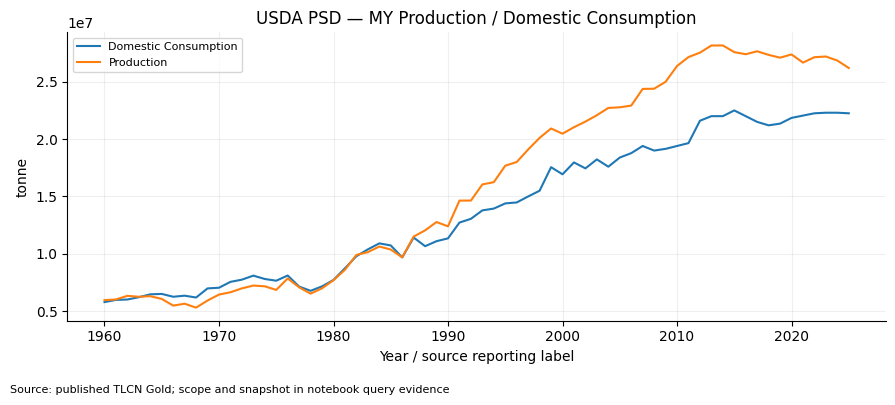

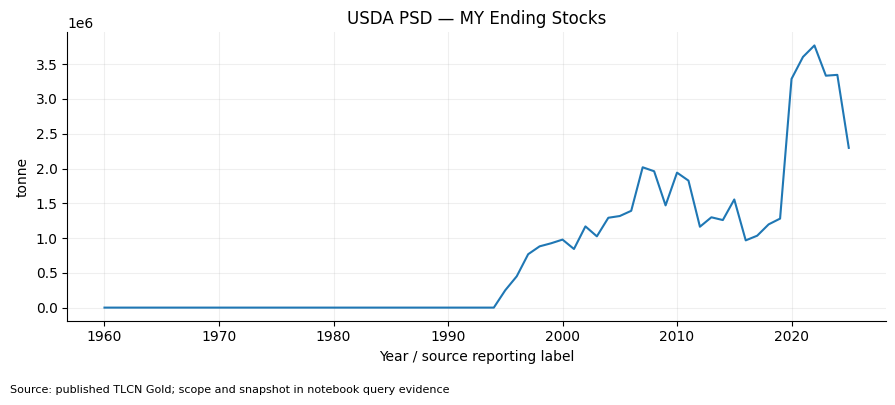

In [11]:
annual_plot(core[core.metric!='Ending Stocks'],'value','USDA PSD — MY Production / Domestic Consumption','tonne',year='market_year',group='metric')
annual_plot(core[core.metric=='Ending Stocks'],'value','USDA PSD — MY Ending Stocks','tonne',year='market_year')

**Nguồn biểu đồ:** published TLCN Gold, batch `ec421297…`. Exact source table/metric/series, units và time filters ở retrieval/validation cells ngay trong section này. Không có interpolation hoặc tự chuyển source identities.

**Diễn giải:** MY không phải calendar year; TY imports/exports và Rough Production vẫn là attributes riêng, không được cộng vào MY hoặc milled totals.

In [12]:
recent=core[core.market_year>=2010]
for identifier,metric in [('PSD01','Production'),('PSD02','Ending Stocks')]:
    stat=endpoint_change(recent[recent.metric==metric],year='market_year')
    findings.append(dict(id=identifier,title='USDA MY '+metric,observation=f"MY {stat['first_year']}–{stat['last_year']}: {stat['first_value']:,.2f} → {stat['last_value']:,.2f} tonnes ({stat['change_pct']:+.2f}%).",scope='USDA PSD Vietnam / Rice, Milled; exact attribute',interpretation='Descriptive marketing-year trend; không reconcile với FAOSTAT calendar observations.',query='psd',cell='Câu hỏi 2',numbers=stat))

## Key Findings

Measured batch `ec421297c194804dc7a3a63aacfda37a65dacfac07245d118e34b34506ca2235`.

### SUA01 — SUA food_supply_quantity_t

**OBSERVATION:** 2010–2023: 14,050,000.00 → 13,837,660.13 tonnes (-1.51%).

**Scope:** FAOSTAT Viet Nam, 23161.02; calendar years

**INTERPRETATION / LIMITATION:** Reported component trend; opening stock is not annual flow and no closing stock is invented.

**Reproduce:** query `sua`, Câu hỏi 1.

### SUA02 — SUA opening_stocks_t

**OBSERVATION:** 2010–2023: 5,917,024.29 → 6,113,011.31 tonnes (+3.31%).

**Scope:** FAOSTAT Viet Nam, 23161.02; calendar years

**INTERPRETATION / LIMITATION:** Reported component trend; opening stock is not annual flow and no closing stock is invented.

**Reproduce:** query `sua`, Câu hỏi 1.

### PSD01 — USDA MY Production

**OBSERVATION:** MY 2010–2025: 26,371,000.00 → 26,200,000.00 tonnes (-0.65%).

**Scope:** USDA PSD Vietnam / Rice, Milled; exact attribute

**INTERPRETATION / LIMITATION:** Descriptive marketing-year trend; không reconcile với FAOSTAT calendar observations.

**Reproduce:** query `psd`, Câu hỏi 2.

### PSD02 — USDA MY Ending Stocks

**OBSERVATION:** MY 2010–2025: 1,941,000.00 → 2,297,000.00 tonnes (+18.34%).

**Scope:** USDA PSD Vietnam / Rice, Milled; exact attribute

**INTERPRETATION / LIMITATION:** Descriptive marketing-year trend; không reconcile với FAOSTAT calendar observations.

**Reproduce:** query `psd`, Câu hỏi 2.

## Limitations

Không cross-provider balance reconciliation; không suy closing stocks SUA, không cộng stocks qua thời gian, không cộng totals với components hoặc MY với TY.

In [13]:
print(save_evidence(ROOT, '03_rice_supply_demand', client, findings))
print('Query audit:')
display(pd.DataFrame(client.evidence)[['query','row_count','query_seconds','response_bytes','batch']])

docs/analytics/evidence/03_rice_supply_demand.json
Query audit:


,query,row_count,query_seconds,response_bytes,batch
0,publication,17,0.000000,4333,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
1,catalogue,987,0.051327,280734,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
2,catalogue,295,0.056773,49096,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
3,subject_products,2,0.258839,4363,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
4,sua,14,0.285776,20630,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
5,psd,990,0.247303,279735,ec421297c194804dc7a3a63aacfda37a65dacfac07245d...
